## Housing data

Predictors:
```
 1. CRIM     per capita crime rate by town
 2. ZN       proportion of residential land zoned for lots over 
             25,000 sq.ft.
 3. INDUS    proportion of non-retail business acres per town
 4. CHAS     Charles River dummy variable (= 1 if tract bounds 
             river; 0 otherwise)
 5. NOX      nitric oxides concentration (parts per 10 million)
 6. RM       average number of rooms per dwelling
 7. AGE      proportion of owner-occupied units built prior to 1940
 8. DIS      weighted distances to five Boston employment centres
 9. RAD      index of accessibility to radial highways
10. TAX      full-value property-tax rate per $10,000
11. PTRATIO  pupil-teacher ratio by town
12. B        1000(Bk - 0.63)^2 where Bk is the proportion of blacks 
             by town
13. LSTAT    % lower status of the population
14. MEDV     Median value of owner-occupied homes in $1000s
```

In [21]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/rasbt/'
                 'python-machine-learning-book-2nd-edition'
                 '/master/code/ch10/housing.data.txt',
                 header=None,
                 sep='\s+')

df.columns = ['CRIM', 'ZN', 'INDUS', 'CHAS', 
              'NOX', 'RM', 'AGE', 'DIS', 'RAD', 
              'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [22]:
df.shape

(506, 14)

### Visualise important characteristics

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

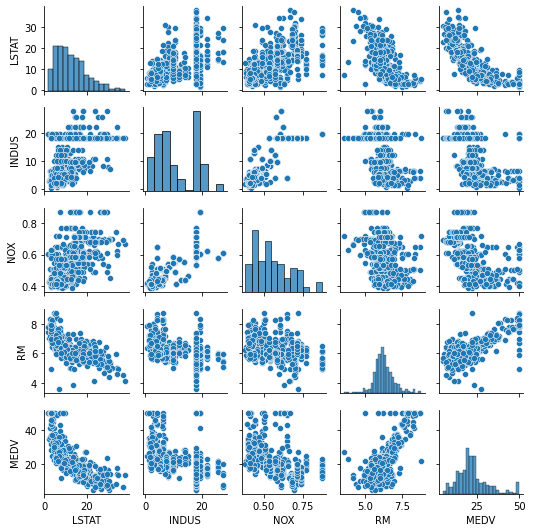

In [5]:
cols = ['LSTAT', 'INDUS', 'NOX', 'RM', 'MEDV']

sns.pairplot(df[cols], height=1.5)
plt.tight_layout()
plt.show()

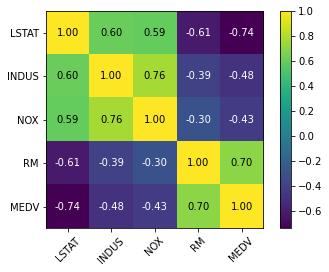

In [6]:
from mlxtend.plotting import heatmap
import numpy as np
cm = np.corrcoef(df[cols].values.T)
(fig,ax) = heatmap(cm,
            row_names=cols,
            column_names=cols)
bottom, top = ax.get_ylim()
#ax.set_ylim(bottom + 0.5, top - 0.5) # This is needed for matplotlib 3.1.1 to compensate for bug
plt.show()

Back to presentation

## Regression parameter estimation with Gradient Descent

In [7]:
class LinearRegressionGD(object):

    def __init__(self, eta=0.001, n_iter=20):
        # Initialise by saving (possibly default) parameters
        self.eta = eta       # Step size
        self.n_iter = n_iter # Epochs

    def fit(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1]) # Internal start weights
        self.cost_ = []                    # Internal start cost

        for i in range(self.n_iter):
            output = self.net_input(X) # Predict output
            errors = (y - output)
            self.w_[1:] += self.eta * X.T.dot(errors) # Update weights (derivative of cost function)
            self.w_[0] += self.eta * errors.sum()     # ------||------ (see Chapter 2 on Grad. Desc.)
            cost = (errors**2).sum() / 2.0            # Current cost (SSE)
            self.cost_.append(cost)
        return self

    def net_input(self, X): # Neural network name of prediction
        return X @ self.w_[1:] + self.w_[0]

    def predict(self, X):
        return self.net_input(X)

#### Simple regression

In [8]:
X = df[['RM']].values
y = df['MEDV'].values

In [9]:
from sklearn.preprocessing import StandardScaler

sc_x = StandardScaler()
sc_y = StandardScaler()
X_std = sc_x.fit_transform(X)
y_std = sc_y.fit_transform(y[:, np.newaxis]).flatten()
# StandardScaler expects 2D-array. np.newaxis adds second dimension, flatten() removes it again

In [10]:
lr = LinearRegressionGD()
lr.fit(X_std, y_std)
# No .score()-method implemented only .predict(). We will plot after showing plot types.

Back to presentation

#### Plot SSE as function of Epochs

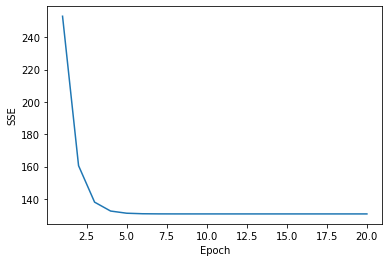

In [11]:
plt.plot(range(1, lr.n_iter+1), lr.cost_)
plt.ylabel('SSE')
plt.xlabel('Epoch')
plt.show()

#### Plot target vs predictor

In [12]:
def lin_regplot(X, y, model):
    plt.scatter(X, y, c='steelblue', edgecolor='white', s=70)
    plt.plot(X, model.predict(X), color='black', lw=2)    
    return

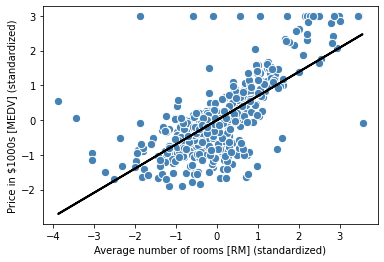

In [13]:
lin_regplot(X_std, y_std, lr)
plt.xlabel('Average number of rooms [RM] (standardized)')
plt.ylabel('Price in $1000s [MEDV] (standardized)')
plt.show()

In [14]:
print('Slope: %.3f' % lr.w_[1])
print('Intercept: %.3f' % lr.w_[0])

Slope: 0.695
Intercept: -0.000


In [15]:
num_rooms_std = sc_x.transform(np.array([[6]])) # Scale (look at distributions above)
print("Number of rooms standardized: %.3f" % num_rooms_std)
price_std = lr.predict(num_rooms_std)
print("Price in $1000s: %.3f" % sc_y.inverse_transform(price_std[:,np.newaxis])) # "Un-scale"

Number of rooms standardized: -0.406
Price in $1000s: 19.942


## OLS via scikit-learn

In [16]:
from sklearn.linear_model import LinearRegression
slr = LinearRegression()
slr.fit(X, y)             # Skipping standardization here
y_pred = slr.predict(X)
print('Slope: %.3f' % slr.coef_[0])
print('Intercept: %.3f' % slr.intercept_)

Slope: 9.102
Intercept: -34.671


In [17]:
# Also in regression, ensembles can be used. 
# Here average prediction across regressors is the outcome.
from sklearn.ensemble import VotingRegressor
ereg = VotingRegressor([('slr', slr), ('slr2', slr)])
ereg.fit(X, y)

VotingRegressor(estimators=[('slr', LinearRegression()),
                            ('slr2', LinearRegression())])

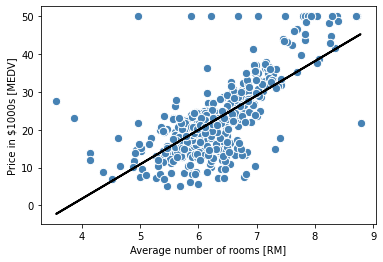

In [18]:
lin_regplot(X, y, slr)
plt.xlabel('Average number of rooms [RM]')
plt.ylabel('Price in $1000s [MEDV]')
#plt.xlim([0,9])
#plt.ylim([-35,51])
plt.show()

Normal Equations alternative:

In [19]:
# adding a column vector of "ones"
Xb = np.hstack((np.ones((X.shape[0], 1)), X)) # Xb = [1 X]
w = np.linalg.inv(Xb.T @ Xb) @ (Xb.T @ y)     # (Xb'*Xb)^-1 * Xb' * y

print('Slope: %.3f' % w[1])
print('Intercept: %.3f' % w[0])

Slope: 9.102
Intercept: -34.671


- Guaranteed optimal solution for non-singular problems.
- Computationally infeasible for huge data sets.

### Diagonstic plot
We will split into training and test for illustration

In [20]:
df.shape

(506, 14)

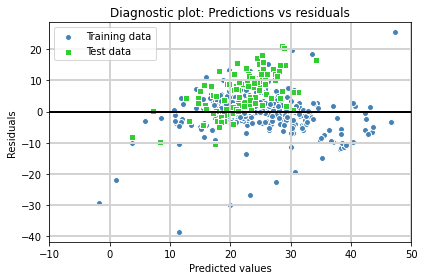

In [21]:
import matplotlib.pyplot as plt

X_train = df[['RM']].values[:400,:]
y_train = df['MEDV'].values[:400]
X_test  = df[['RM']].values[400:,:]
y_test  = df['MEDV'].values[400:]

slr.fit(X_train, y_train)
y_train_pred = slr.predict(X_train)
y_test_pred  = slr.predict(X_test)

# Caluculate the residuals:
res_train = y_train_pred - y_train
res_test  = y_test_pred  - y_test

# Make the diagnostic plot
plt.scatter(y_train_pred, res_train,
            c='steelblue', marker='o', edgecolor='white',
            label='Training data')
plt.scatter(y_test_pred, res_test,
            c='limegreen', marker='s', edgecolor='white',
            label='Test data')
plt.xlabel('Predicted values')
plt.ylabel('Residuals')
plt.title('Diagnostic plot: Predictions vs residuals')
plt.legend(loc='upper left')
plt.hlines(y=0, xmin=-10, xmax=50, color='black', lw=2)
plt.xlim([-10, 50])
plt.tight_layout()
plt.grid(color='LightGrey', linestyle='-', linewidth=2)
plt.show()

Are we satisfied with my manual train-test-split?

### Performance metrics to assess model "goodness"
Assume that $y^{(i)}$ and $\hat{y}^{(i)}$ are the true and predicted target values of sample number $(i)$ among $n$ samples. Then  
 - the __Mean Squared Error (MSE)__ is defined as $MSE = \frac{1}{n}SSE$, where $SSE =\sum_{i = 1}^{n}(y^{(i)}-\hat{y}^{(i)})^2$, i.e. the average value of the squared errors.
 - the __Mean Absolute Error (MAE)__ is defined as $MAE = \frac{1}{n}\sum_{i = 1}^{n}|y^{(i)}-\hat{y}^{(i)}|$, i.e. the average of the absolute errors.
 - the __Coefficient of Determination__ is defined as $R^2= 1 - \frac{SSE}{SST}$, where $SST = \sum_{i = 1}^{n}(y^{(i)}-\bar{y})^2$ and $\bar{y}=\frac{1}{n}y^{(i)}$ is the average target value.

In [22]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

print('Mean squared error (MSE)  - train: %.3f, test: %.3f' % (
        mean_squared_error(y_train, y_train_pred),
        mean_squared_error(y_test, y_test_pred)))
print('R^2                       - train:  %.3f, test: %.3f' % (
        r2_score(y_train, y_train_pred),
        r2_score(y_test, y_test_pred)))
print('Mean absolute error (MAE) - train: %.3f,  test:  %.3f' % (
        mean_absolute_error(y_train, y_train_pred),
        mean_absolute_error(y_test, y_test_pred)))

Mean squared error (MSE)  - train: 36.303, test: 79.626
R^2                       - train:  0.567, test: -1.818
Mean absolute error (MAE) - train: 3.827,  test:  7.375


In [23]:
print('Root mean squared error (RMSE) - train: %.3f, test: %.3f' % (
        np.sqrt(mean_squared_error(y_train, y_train_pred)),
        np.sqrt(mean_squared_error(y_test, y_test_pred))))

Root mean squared error (RMSE) - train: 6.025, test: 8.923


Back to presentation

## RANSAC

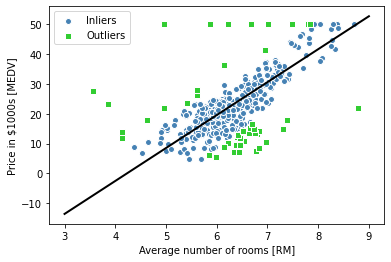

In [29]:
from sklearn.linear_model import RANSACRegressor

ransac = RANSACRegressor(LinearRegression(), 
                         max_trials=100,         # Number of iterations of the loop
                         min_samples=50,         # Minimum random sample size
                         loss='absolute_error',  # Loss function for outliers (vertical distance)
                         residual_threshold=10.0,# Maximum vertical distance in MAD units (test me!)
                         stop_score=0.99,        # Stop searching if inliers score >= 0.99
                         random_state=0)

ransac.fit(X, y)

# Final choice of inliers and outliers
inlier_mask = ransac.inlier_mask_          
outlier_mask = np.logical_not(inlier_mask)

line_X = np.arange(3, 10, 1) # Regression line
line_y_ransac = ransac.predict(line_X[:, np.newaxis])
plt.scatter(X[inlier_mask], y[inlier_mask],
            c='steelblue', edgecolor='white', 
            marker='o', label='Inliers')
plt.scatter(X[outlier_mask], y[outlier_mask],
            c='limegreen', edgecolor='white', 
            marker='s', label='Outliers')
plt.plot(line_X, line_y_ransac, color='black', lw=2)   
plt.xlabel('Average number of rooms [RM]')
plt.ylabel('Price in $1000s [MEDV]')
plt.legend(loc='upper left')
plt.show()

In [30]:
# From RANSAC estimated inliers:
print('Score: %.3f' % ransac.score(X,y))
print('Slope: %.3f' % ransac.estimator_.coef_[0])
print('Intercept: %.3f' % ransac.estimator_.intercept_)
print('Iterations applied: %d' % ransac.n_trials_)

Score: 0.462
Slope: 11.026
Intercept: -46.621
Iterations applied: 100


In [31]:
# From all data points:
print('Score: %.3f' % slr.score(X,y))
print('Slope: %.3f' % slr.coef_[0])
print('Intercept: %.3f' % slr.intercept_)

Score: 0.484
Slope: 9.102
Intercept: -34.671


Back to presentation